In [1]:
%reload_ext autoreload
%autoreload 2

import warnings, os, sys
warnings.filterwarnings('ignore')
from IPython.display import clear_output

import numpy as np
import pandas as pd
import swifter
from functools import reduce
from tqdm.auto import tqdm

from rdkit import Chem
from rdkit.Chem import PandasTools
PandasTools.RenderImagesInAllDataFrames(images=True)
from rdkit import RDLogger; RDLogger.DisableLog('rdApp.*')
from rdkit.DataStructs import TanimotoSimilarity
from rdkit.Chem.AllChem import GetMorganFingerprintAsBitVect
from rdkit.Chem import Descriptors

from rdkit.Chem.Draw import IPythonConsole
IPythonConsole.ipython_useSVG = True
IPythonConsole.molSize = 600, 400
IPythonConsole.drawOptions.addAtomIndices = False

import plotly.express as px
import plotly.graph_objects as go
import plotly.io as pio
pio.renderers.default = "notebook"
pio.renderers.default_config = {"toImageButtonOptions": {"format": "png", "scale": 5}}

# sys.path.append(os.path.abspath(".."))
# from new_geass import Geass

sys.path.append(os.path.abspath(R"C:\\Users\\Idener\\Sync\\CODE"))
from AIDDTools import fingerprint_tools as fpt
clear_output()

ModuleNotFoundError: No module named 'swifter'

In [ ]:
df_BUL = pd.read_pickle('../data/Database_NEWBUL.pkl')

df_NPA = pd.read_csv('../data/NPAtlas_download_2024_09.tsv', sep='\t')
PandasTools.AddMoleculeColumnToFrame(df_NPA, smilesCol='compound_smiles')

In [5]:
# Palettes
#* https://www.molecularecologist.com/2020/04/23/simple-tools-for-mastering-color-in-scientific-figures/
#* https://github.com/OrdnanceSurvey/GeoDataViz-Toolkit/blob/master/Colours/GDV-colour-palettes.json

geodataviz_diverging_1 = ["#045275", "#089099", "#39B185", "#7CCBA2", "#FCDE9C",
                          "#EEB479", "#E88471", "#7C1D6F", "#CF597E", "#9A275A"]
node_colors = {'red': '#d10808', 'yellow': '#ffc32d', 'green': '#009b73'}

## Fragment NP Atlas

In [ ]:
# Fragment molecules and write to file in batches

with open('geass_NPA_fragments.csv', 'a') as f:
    buffer = []
    for row in tqdm(df_NPA.itertuples(), total=df_NPA.shape[0]):
        try:
            geass = Geass()
            fragments = [Chem.MolToSmiles(x) for x in geass.get_fragments(row.ROMol)]
            fragments_str = '[' + ','.join(fragments) + ']'
        except:
            fragments_str = '[ERROR]'
        line = f'{row.npaid},{row.compound_smiles},"{fragments_str}"\n'
        buffer.append(line)
        
        if len(buffer) == 1000:
            f.writelines(buffer)
            buffer.clear()
    
    # Final flush
    if buffer:
        f.writelines(buffer)

In [ ]:
# Assign KEGG- or U-ID to fragments
df_frags = pd.read_csv('geass_NPA_fragments.csv', sep=',', header=None)

df_frags.columns = ['ID', 'SMILES', 'Fragments']
df_frags['Fragments'] = df_frags['Fragments'].str.strip('[]').str.split(',')

df_unfragmented = df_frags[df_frags['Fragments'].apply(len) == 1]
df_fragmented = df_frags[df_frags['Fragments'].apply(len) > 1]
# df_error = df_unfrag[df_unfrag['Fragments'].apply(lambda x: 'ERROR' in x)]

uul = {}
id_list = []
for frag_list in tqdm(df_fragmented['Fragments'].tolist()):
    ids = []
    for smi in frag_list:
        inchi = Chem.MolToInchi(Chem.MolFromSmiles(smi))
        bu = df_BUL[df_BUL['InChI'] == inchi]

        if bu.shape[0] > 0:
            id = bu['ID'].values[0]
        else:
            # Mark as unknown compound
            id = uul.setdefault(smi, f"U{len(uul)+1:05d}")
        ids.append(id)

    id_list.append(ids)
df_fragmented['Frag_IDs'] = id_list

df_fragmented.to_pickle('geass_NPA_fragmented.pkl')
df_unfragmented.to_pickle('geass_NPA_unfragmented.pkl')

# Create the unknown unit library
df_UUL = pd.DataFrame([(v, k) for k, v in uul.items()], columns=['UID', 'ISOSMILES'])
PandasTools.AddMoleculeColumnToFrame(df_UUL, smilesCol='ISOSMILES')
df_UUL = df_UUL.dropna(subset=['ROMol'])
df_UUL.drop(columns=['ROMol']).to_csv('../data/Database_UUL.csv', index=False)
df_UUL.to_pickle('../data/Database_UUL.pkl')

## Work on UUs

In [47]:
# df_metacyc = pd.read_csv(R"C:\Users\Idener\Desktop\biosynthetic_chains_smiles.tsv", sep='\t', header=None)

# Extract adjacent pairs of SMILES
# pairs = []
# for _, row in df_metacyc.iterrows():
#     smiles_chain = [s for s in row if pd.notna(s) and str(s).strip() != ""]
#     for i in range(len(smiles_chain) - 1):
#         pairs.append((smiles_chain[i], smiles_chain[i+1]))
# df_pairs = pd.DataFrame(pairs, columns=["Reactant", "Product"])
# PandasTools.AddMoleculeColumnToFrame(df_pairs, smilesCol='Reactant', molCol='ROMol_R')
# PandasTools.AddMoleculeColumnToFrame(df_pairs, smilesCol='Product', molCol='ROMol_P')

# df_pairs['MACCS_R'] = df_pairs['ROMol_R'].swifter.apply(lambda x: fpt.calculate_fp(x, method='maccs'))
# df_pairs['MACCS_P'] = df_pairs['ROMol_P'].swifter.apply(lambda x: fpt.calculate_fp(x, method='maccs'))
# df_pairs['Similarity_MACCS'] = df_pairs.swifter.apply(lambda row: fpt.get_similarity(row['MACCS_R'], row['MACCS_P'], 'maccs'), axis=1)

df_pairs['MAP4_R'] = df_pairs['ROMol_R'].swifter.apply(lambda x: fpt.calculate_fp(x, method='map4'))
df_pairs['MAP4_P'] = df_pairs['ROMol_P'].swifter.apply(lambda x: fpt.calculate_fp(x, method='map4'))
df_pairs['Similarity_MAP4'] = df_pairs.swifter.apply(lambda row: fpt.get_similarity(row['MAP4_R'], row['MAP4_P'], 'map4'), axis=1)

df_pairs

NameError: name 'tm' is not defined

In [22]:
# Calculate similarity matrix between df_UUL and df_BUL
# df_UUL = pd.read_pickle('../data/Database_UUL.pkl')
# df_BUL = pd.read_pickle('../data/Database_NEWBUL.pkl')

method = 'MACCS'

fps_1 = df_UUL['ROMol'].swifter.apply(lambda x: fpt.calculate_fp(x, method=method))
fps_2 = df_BUL['ROMol'].swifter.apply(lambda x: fpt.calculate_fp(x, method=method))
sim_matrix = fpt.get_similarity_matrix(fps_1, fps_2, method=method)
# np.savez_compressed(f"UUL_similarity_matrix_{method}.npz", sim_matrix=sim_matrix)

Pandas Apply:   0%|          | 0/15720 [00:00<?, ?it/s]

Pandas Apply:   0%|          | 0/16357 [00:00<?, ?it/s]


*** Using vectorized Tanimoto similarity calculation ***



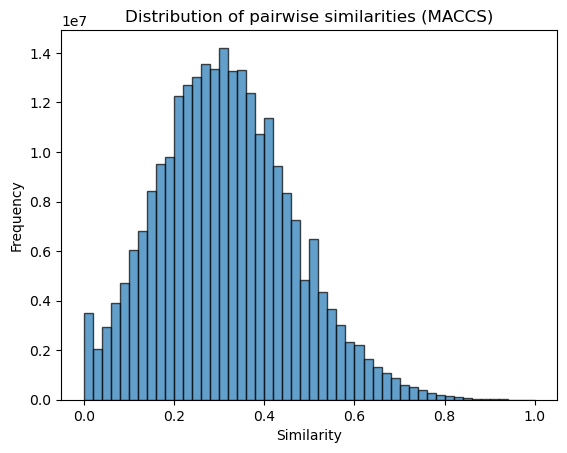

Quantiles (5%,25%,50%,75%,95%): [0.082 0.21  0.308 0.41  0.571]


In [23]:
import numpy as np
import matplotlib.pyplot as plt

# Flatten similarity matrix (ignore diagonal if fps_1 is fps_2)
all_scores = sim_matrix.flatten()
if fps_1 is fps_2:  # self-similarity case
    all_scores = all_scores[~np.eye(sim_matrix.shape[0], dtype=bool)]

# Plot histogram
plt.hist(all_scores, bins=50, edgecolor='black', alpha=0.7)
plt.xlabel("Similarity")
plt.ylabel("Frequency")
plt.title(f"Distribution of pairwise similarities ({method})")
plt.show()

# Optional: print some quantiles to see typical ranges
quantiles = np.quantile(all_scores, [0.05, 0.25, 0.5, 0.75, 0.95])
print("Quantiles (5%,25%,50%,75%,95%):", quantiles)


In [24]:
"""
Match UUL molecules to the most similar BU.

For each molecule in the UUL dataset:
- Sort the BUL similarities in descending order.
- Identify the most similar BUL molecule with a Tanimoto similarity ≥ 0.6.
- Accept the match only if the number of heavy atoms differs by no more than 3.
- Record UID, ISOSMILES from UUL and ID, ISOSMILES from BUL along with the similarity score.
"""

data = []
for u_idx, row in enumerate(sim_matrix):
    uid_atoms = df_UUL.iloc[u_idx]['ROMol'].GetNumHeavyAtoms()
    sorted_indices = np.argsort(row)[::-1]
    sorted_values = row[sorted_indices]

    aux_list = [df_UUL.iloc[u_idx]['UID'], df_UUL.iloc[u_idx]['ISOSMILES']]
    for k_idx, sim_value in zip(sorted_indices, sorted_values):
        if sim_value >= 0.8:
            kid_atoms = df_BUL.iloc[k_idx]['ROMol'].GetNumHeavyAtoms()
            if abs(uid_atoms - kid_atoms) <= 3:
                aux_list.extend([df_BUL.iloc[k_idx]['ID'],
                                df_BUL.iloc[k_idx]['ISOSMILES'],
                                float(sim_value)])
                break
    if len(aux_list) == 2:
        aux_list.extend([None, None, None])
    data.append(aux_list)

df_UUL_sim = pd.DataFrame(data, columns=['UID', 'ISOSMILES', 'Similar_KID', 'Similar_ISOSMILES', 'Similarity'])
df_UUL_sim.to_csv(f'../data/Database_UUL_{method}.csv', index=False)

In [ ]:
df_UUL = pd.read_csv(f'../data/Database_UUL_{method}.csv')
df_fragmented = pd.read_pickle('geass_NPA_fragmented.pkl')

fragmented_sim, sim_values = [], []
for lst in tqdm(df_fragmented['Frag_IDs'].tolist()):
    lst_aux1, lst_aux2 = [], []
    for id in lst:
        if 'U' in id:
            df_aux = df_UUL[df_UUL['UID'] == id]
            if df_aux.shape[0] > 0:
                if df_aux['Similarity'].values[0] == 1:  #<-- Some units are not recognised by geass due to tautomerism/chirality
                    kid = df_aux['Similar_KID'].values[0]
                    lst_aux1.append(kid)
                    lst_aux2.append(1.0)

                elif df_aux['Similarity'].values[0] >= 0.6:
                    kid = df_aux['Similar_KID'].values[0]
                    lst_aux1.append(f"~{kid}")
                    lst_aux2.append(df_aux['Similarity'].values[0])
                else:
                    lst_aux1.append(id)
                    lst_aux2.append(0.0)
            else:
                lst_aux1.append(id)
                lst_aux2.append(0.0)
        else:
            lst_aux1.append(id)
            lst_aux2.append(0.0)
                
    fragmented_sim.append(lst_aux1)
    sim_values.append([float(x) for x in lst_aux2])

df_fragmented['Frag_sim_IDs'] = fragmented_sim
df_fragmented['Frag_sim_values'] = sim_values

df_fragmented.to_pickle('geass_NPA_fragmented.pkl')

## Analysis of the unknown unit library

In [ ]:
df_UUL_sim = pd.read_csv(f'../data/Database_UUL_{method}.csv')

# Define bin edges and labels
bins = np.linspace(0, 1, 11)  # 0.0, 0.1, ..., 1.0
bins = np.append(bins, 1.0001)  # Extend upper bound slightly to include 1.0 with right=False
bin_labels = [f"{bins[i]:.2f}-{bins[i+1] - 0.01:.2f}" for i in range(len(bins) - 2)] + ["1 (exact)"]

# Bin the similarity values with left-inclusive, right-exclusive intervals
df_UUL_sim['Similarity_Bin'] = pd.cut(df_UUL_sim['Similarity'], bins=bins, labels=bin_labels,
                                  include_lowest=True, right=False)

# Count values per bin and prepare DataFrame for plotting
counts = df_UUL_sim['Similarity_Bin'].value_counts().sort_index()
hist_df = pd.DataFrame({
    'Bin': bin_labels,
    'Count': counts.values,
    'Text': [str(c) for c in counts.values]})
hist_df['Color'] = ['#d10808'] * 6 + ['#ffc32d'] * 4 + ['#009b73']

In [ ]:
# Plot histogram using Plotly
fig = px.bar(
    hist_df,
    x='Bin',
    y='Count',
    text='Text',
    color='Color',
    color_discrete_map='identity',  # use exact color names
    labels={'Bin': f'Similarity Range ({method})', 'Count': 'Frequency'})

fig.update_layout(
    xaxis_title= f'Similarity Range ({method})',
    yaxis_title='Count',
    font=dict(family="sans-serif"),
    bargap=0.1,
    width=800,
    height=400)

fig.show(config={"toImageButtonOptions": {"format":"svg", "scale":5}})

print(f"""======= UUL Summary =======
      
UUs with direct annotation: {len(df_UUL[df_UUL['Similarity'] == 1])}
UUs with similarity annotation (sim >= 0.6): {len(df_UUL[(df_UUL['Similarity'] < 1) & (df_UUL['Similarity'] >= 0.6)])}
UUs with no annotation (sim < 0.6): {len(df_UUL[df_UUL['Similarity'] < 0.6])}
Total UUs: {len(df_UUL)}
""")

## Analysis of fragments

In [ ]:
df_fragmented = pd.read_pickle('geass_NPA_fragmented.pkl')

# Count nodes before and after similarity search
green_initial = df_fragmented['Frag_IDs'].apply(lambda x: [i for i in x if i.startswith('C')])
red_initial = df_fragmented['Frag_IDs'].apply(lambda x: [i for i in x if i.startswith('U')])
green_final = df_fragmented['Frag_sim_IDs'].apply(lambda x: [i for i in x if i.startswith('C')])
yellow_final = df_fragmented['Frag_sim_IDs'].apply(lambda x: [i for i in x if i.startswith('~')])
red_final = df_fragmented['Frag_sim_IDs'].apply(lambda x: [i for i in x if i.startswith('U')])

In [ ]:
# Prepare data
summary_data = {
    'Annotation': ['Direct', 'None', 'Direct', 'By similarity', 'None'],
    'Stage': ['Before'] * 2 + ['After'] * 3,
    'Count': [
        green_initial.apply(len).sum(),
        red_initial.apply(len).sum(),
        green_final.apply(len).sum(),
        yellow_final.apply(len).sum(),
        red_final.apply(len).sum()]}

summary_df = pd.DataFrame(summary_data)

# Plot grouped bar chart
fig = px.bar(
    summary_df,
    x='Stage',
    y='Count',
    color='Annotation',
    barmode='group',
    text='Count',
    color_discrete_map={
        'Direct': '#009b73',
        'By similarity': '#ffc32d',
        'None': '#d10808'
    }
)

fig.update_layout(
    # title='Node annotation',
    xaxis_title='Annotation Stage',
    yaxis_title='Number of nodes',
    font=dict(family="sans-serif"),
    width=800,
    height=400
)

fig.show(config={"toImageButtonOptions": {"format":"svg", "scale":5}})

print(f"""======= Node Summary =======
    
*** Before similarity search ***
Green nodes: {green_initial.apply(len).sum()}
Red nodes:   {red_initial.apply(len).sum()}
Total nodes: {green_initial.apply(len).sum() + red_initial.apply(len).sum()}

*** After similarity search ***
Green nodes:  {green_final.apply(len).sum()}
Yellow nodes: {yellow_final.apply(len).sum()}
Red nodes:    {red_final.apply(len).sum()}
Total nodes:  {green_final.apply(len).sum() + yellow_final.apply(len).sum() + red_final.apply(len).sum()}
""")


In [ ]:
# Before similarity search
ids = df_fragmented['Frag_IDs']
all_green_i = ids.apply(lambda x: all(id.startswith('C') for id in x))
some_red_i = ids.apply(lambda x: any(id.startswith('U') for id in x))

# After similarity search
sim_ids = df_fragmented['Frag_sim_IDs']
all_green_f = sim_ids.apply(lambda x: all(id.startswith('C') for id in x))
some_red_f = sim_ids.apply(lambda x: any(id.startswith('U') for id in x))
green_yellow_f = ~all_green_f & ~some_red_f

In [ ]:
# Prepare data
summary_data = {
    'Status': ['all green nodes', 'at least one red node',
               'all green nodes', 'at least one red node', 'green+yellow nodes'],
    'Stage': ['Before', 'Before', 'After', 'After', 'After'],
    'Count': [all_green_i.sum(), some_red_i.sum(),
              all_green_f.sum(), some_red_f.sum(), green_yellow_f.sum()]}

summary_df = pd.DataFrame(summary_data)

# Plot grouped bar chart
fig = px.bar(
    summary_df,
    x='Stage',
    y='Count',
    color='Status',
    color_discrete_map=dict(zip(summary_df['Status'].unique(),
                                geodataviz_diverging_1)),
    barmode='group',
    text='Count',
#     color_discrete_map={
#     'all green nodes': '#1f77b4',       # Blue
#     'green+red or all red nodes': '#9467bd',   # Purple
#     'green+yellow+red nodes': '#ff7f0e'  # Orange
# }
)

fig.update_layout(
    # title='Compound annotation',
    xaxis_title='Annotation Stage',
    yaxis_title='Number of compounds',
    font=dict(family="sans-serif"),
    width=800,
    height=400
)

fig.show(config={"toImageButtonOptions": {"format":"svg", "scale":5}})

print(f"""======= Fragmentation Summary =======

*** Before similarity search ***
{all_green_i.sum()} compounds with direct annotations (all green nodes)
{some_red_i.sum()} compounds lacking full annotation (g+r or all red)
Total compounds = {(all_green_i | some_red_i).sum()}

*** After similarity search ***
{all_green_f.sum()} compounds with direct annotations (all green nodes)
{green_yellow_f.sum()} compounds with similarity annotation (g+y or all yellow nodes)
{some_red_f.sum()} compounds lacking full annotation (at least one red node)
Total compounds = {(all_green_f | green_yellow_f | some_red_f).sum()}
""")

In [ ]:
n_atom_list = []
for row in df_fragmented.itertuples():
    aux = []
    for smi in row.Fragments:
        try:
            aux.append(Chem.MolFromSmiles(smi).GetNumAtoms())
        except:
            aux.append(0)
    n_atom_list.append(aux)
df_fragmented['Frag_N_atoms'] = n_atom_list

percent_gy_nodes = []
for row in df_fragmented.itertuples():
    indices = [i for i, id in enumerate(row.Frag_sim_IDs) if not 'U' in id]
    n_atom_red_nodes = sum(row.Frag_N_atoms[i] for i in indices)
    n_atom_compound = sum(row.Frag_N_atoms)
    percent_gy_nodes.append(round(n_atom_red_nodes/n_atom_compound*100, 2))
df_fragmented['Percent_gy_nodes'] = percent_gy_nodes

In [ ]:
# Filter out 0% entries
percentages = df_fragmented[df_fragmented['Percent_gy_nodes'] != 0]['Percent_gy_nodes']

bins = np.linspace(0, 100, 11)  # [0, 10, ..., 100]
bins[-1] += 0.1  # extend last bin to include 100.0
bin_labels = [f"{int(bins[i])}-{int(bins[i+1])}%" for i in range(len(bins) - 1)]

# Bin the values
binned = pd.cut(percentages, bins=bins, labels=bin_labels,
                include_lowest=True, right=False)

# Count frequencies
hist_df = binned.value_counts().sort_index().reset_index()
hist_df.columns = ['Bin', 'Count']
hist_df['Text'] = hist_df['Count'].astype(str)

# Plot
fig = px.bar(
    hist_df,
    x='Bin',
    y='Count',
    text='Text',
    # title='Coverage of green+yellow nodes in compounds',
    labels={'Bin': 'Percentage of annotated atoms', 'Count': 'Compound count'}
)

fig.update_layout(
    xaxis_title='Percentage of annotated atoms',
    yaxis_title='Number of compounds',
    font=dict(family="sans-serif"),
    bargap=0.1,
    width=800,
    height=400
)

fig.show(config={"toImageButtonOptions": {"format":"svg", "scale":5}})


In [ ]:
df_exploded = df_fragmented[['ID', 'Frag_sim_IDs', 'Frag_sim_values']].explode(['Frag_sim_IDs', 'Frag_sim_values'])
df_exploded = df_exploded[df_exploded['Frag_sim_IDs'].str.contains('~')]
df_exploded = df_exploded.groupby(['Frag_sim_IDs']).agg(list).reset_index()
df_exploded['Num_compounds'] = df_exploded['ID'].apply(len)
df_exploded['Avg_Similarity'] = df_exploded['Frag_sim_values'].apply(lambda x: round(sum(x) / len(x), 2) if x else 0)

bins = np.arange(0.60, 1.01, 0.10)
bin_labels = [f"{bins[i]:.2f}-{bins[i+1] - 0.01:.2f}" for i in range(len(bins) - 1)]

df_exploded['Similarity_Bin'] = pd.cut(
    df_exploded['Avg_Similarity'],
    bins=bins,
    labels=bin_labels,
    include_lowest=True,
    right=False
)

hist_df = df_exploded.groupby('Similarity_Bin')['Num_compounds'].sum().reset_index()
hist_df.columns = ['Bin', 'Count']
hist_df['Text'] = hist_df['Count'].astype(str)

fig = px.bar(
    hist_df,
    x='Bin',
    y='Count',
    text='Text',
    # title='Importance of yellow nodes in compounds',
    labels={'Bin': 'Similarity Range', 'Count': 'Frequency'}
)

fig.update_layout(
    xaxis_title='Average similarity range',
    yaxis_title='Number of compounds',
    font=dict(family="sans-serif"),
    bargap=0.1,
    width=800,
    height=400
)

fig.show(config={"toImageButtonOptions": {"format":"svg", "scale":5}})
# fig.write_image("hist_05.png", format="png", scale=5)

print('''NB: the sum of compounds in the bins is not equal to the total number of compounds
because some compounds have multiple yellow nodes with different similarity values.''')

In [ ]:
df_UUL_grouped = df_UUL.groupby('Similar_ISOSMILES').agg(list).reset_index()
df_UUL_grouped['Num_compounds'] = df_UUL_grouped['UID'].apply(len)
df_UUL_grouped['Similar_KID'] = df_UUL_grouped['Similar_KID'].apply(lambda x: list(set(x))[0])

bin_edges = range(0, df_UUL_grouped['Num_compounds'].max() + 10, 10)
df_UUL_grouped['Compound_bin'] = pd.cut(df_UUL_grouped['Num_compounds'], bins=bin_edges, right=False)

# Count the number of Similar_ISOSMILES entries in each bin
bin_counts = df_UUL_grouped['Compound_bin'].value_counts().sort_index()

# Create a bar chart
fig = px.bar(
    x=bin_counts.index.astype(str), 
    y=bin_counts.values,
    labels={'x': 'Number of Compounds (Binned)', 'y': 'Count of Similar_ISOSMILES Groups'},
)

fig.show()

In [ ]:
import plotly.express as px
import pandas as pd

# Explode and remove red nodes (U)
all_ids = df_fragmented['Frag_sim_IDs'].explode()
all_ids = all_ids[~all_ids.str.startswith('U')]

# Count frequency
freq = all_ids.value_counts().reset_index()
freq.columns = ['ID', 'Count']

# Add category column
freq['Category'] = freq['ID'].apply(lambda x: 'Green (C)' if x.startswith('C') else 'Yellow (~)')

# Top 25 green
top_green = freq[freq['Category'] == 'Green (C)'].head(25)
fig_green = px.bar(
    top_green,
    x='ID',
    y='Count',
    color_discrete_sequence=['green'],
    labels={'ID': 'BU', 'Count': 'Occurrence'},
    title='Top 25 Green BUs'
)
fig_green.update_layout(
    xaxis={'categoryorder': 'total descending'},
    width=900,
    height=500
)

# Top 25 yellow
top_yellow = freq[freq['Category'] == 'Yellow (~)'].head(25)
fig_yellow = px.bar(
    top_yellow,
    x='ID',
    y='Count',
    color_discrete_sequence=['gold'],
    labels={'ID': 'BU', 'Count': 'Occurrence'},
    title='Top 25 Yellow BUs'
)
fig_yellow.update_layout(
    xaxis={'categoryorder': 'total descending'},
    width=900,
    height=500
)

# Show plots
fig_green.show()
fig_yellow.show()

In [ ]:
# Get top 25 green and yellow nodes
top_green = freq[freq['Category'] == 'Green (C)'].head(24)
top_yellow = freq[freq['Category'] == 'Yellow (~)'].head(24)

# Get corresponding mol from df_BUL
top_green['ROMol'] = top_green['ID'].apply(lambda x: df_BUL[df_BUL['ID'] == x]['ROMol'].values[0])
top_yellow['ROMol'] = top_yellow['ID'].apply(lambda x: df_BUL[df_BUL['ID'] == x.replace('~', '')]['ROMol'].values[0])

import mols2grid
mols2grid.display(top_green,
    mol_col='ROMol',
    n_items_per_page=25,
    sub_img_size=(200, 200),
    style={"ID": lambda x: "font-weight: bold;"},
    subset=["ID", "Count"],
    use_svg=True,
    show_index=False)

In [ ]:
mols2grid.display(top_yellow,
    mol_col='ROMol',
    n_items_per_page=25,
    sub_img_size=(200, 200),
    style={"ID": lambda x: "font-weight: bold;"},
    subset=["ID", "Count"],
    use_svg=True,
    show_index=False)

## Analysis of unfragmented compounds

In [ ]:
# df_unfragmented = pd.read_pickle('geass_NPA_unfragmented.pkl')
# PandasTools.AddMoleculeColumnToFrame(df_unfragmented, smilesCol='SMILES')
df_unfragmented['FP'] = df_unfragmented['ROMol'].apply(lambda mol: calculate_fp(mol, method='torsion'))
df_unfragmented['MW'] = df_unfragmented['ROMol'].apply(lambda x: Descriptors.MolWt(x))

for i, row in tqdm(df_unfragmented.iterrows(), total=df_unfragmented.shape[0]):
    # Reduce the number of compounds by filtering BUs by MW
    f_aux = df_BUL[(df_BUL['MW'] - 70 <= row['MW']) & (df_BUL['MW'] + 70 >= row['MW'])]

    if len(df_aux) > 0:
        df_aux['similarity'] = df_aux['FP'].apply(lambda x: TanimotoSimilarity(x, row.FP))

        max = df_aux.loc[df_aux['similarity'].idxmax()]
        if max['similarity'] == 1:
            df_unfragmented.loc[i, 'Exact_KID'] = max.ID
        elif max['similarity'] >= 0.6:
            df_unfragmented.loc[i, 'Similar_KID'] = max.ID
            df_unfragmented.loc[i, 'Similar_ISOSMILES'] = max.ISOSMILES
df_unfragmented

In [ ]:
from molcomplib import MolCompass
compass = MolCompass()

df_unfragmented = pd.read_pickle('geass_NPA_unfragmented.pkl')

res = compass.process(df_unfragmented)

In [ ]:
from bokeh_graph import bokeh_plot

df_match = df_unfragmented[(df_unfragmented['Exact_KID'].notna()) | (df_unfragmented['Similar_KID'].notna())]
df_match['Matched_ID'] = df_match['Exact_KID'].fillna(df_match['Similar_KID'])
df_match = df_match.merge(df_BUL[['ID', 'BRITE']], left_on='Matched_ID', right_on='ID', how='left')
df_match = df_match.dropna(subset=['BRITE'])
df_match['BRITE_code'] = df_match['BRITE'].apply(lambda x: x.split('[')[1].split(']')[0].strip())
df_match['BRITE_code'] = df_match.apply(
    lambda row: row['BRITE'].split('\n')[2].strip() if row['BRITE_code'] in ['BR:br08002'] else row['BRITE_code'],
    axis=1
)
df_match['BRITE_code_int'] = df_match['BRITE_code'].astype('category').cat.codes

bokeh_plot(df_match, "BRITE_code_int", id_field="npaid",
           smiles_column='compound_smiles',
           additional_labels=["origin_type", "BRITE_code"])

In [ ]:
print(f'''
    NP Atlas > {len(df_NPA)} total compounds
               {len(fragmented)} compounds fragmented
                  {len(complete)} compounds with direct annotations (all green nodes)
                  {sum(1 for lst in fragmented_sim if any('~' in x for x in lst))} compounds with similarity annotation (g+y+r nodes)
               {len(whole)} compounds not fragmented
                  {len(df_unfragmented['Exact_KID'].dropna())} compounds with direct annotation (one green node)
                  {len(df_unfragmented['Similar_KID'].dropna())} compounds with similarity annotation (one yellow node)
                  {len(whole)-len(df_unfragmented['Exact_KID'].dropna())-len(df_unfragmented['Similar_KID'].dropna())} compounds with no annotation (one red node)

    Building units > {len(df_BUL)} total BUs in BUL
                     {len(set(x for lst in fragmented_sim for x in lst if 'C' in x))} unique BUs recognized
                     {len(set(x for lst in fragmented_sim for x in lst if '~' in x))} similar BUs recognized
                     {len(set(x for lst in fragmented_sim for x in lst if x.startswith('U')))} BUs not recognized
      ''')

In [ ]:
# replace '' with 0.5
df_UUL['Similarity'] = df_UUL['Similarity'].replace('NA', 0.0)
df_UUL['Similarity'] = df_UUL['Similarity'].astype(float)


## Case Study: Beauverichelin A and Forazoline A

In [ ]:
database3 = pd.read_csv('../data/Database3.csv')
database3 = database3[~database3['ID'].str.contains('SS')]
PandasTools.AddMoleculeColumnToFrame(database3, smilesCol='ISOSMILES')

In [ ]:
# # Find compounds with the highest number of different bonds
# data = []
# for row in database3.itertuples():
#     try:
#         geass = Geass()
#         f = geass.get_fragments(row.ROMol)
#         b = set(list(geass.get_bonds_to_break().values()))
#         data.append([row.ID, f, b])
#     except: pass

# df_data = pd.DataFrame(data, columns=['ID', 'Fragments', 'Bonds'])
# df_data['n_bonds'] = df_data['Bonds'].apply(lambda x: len(x))
# df_data = df_data.sort_values(by='n_bonds', ascending=False)
# df_data.head(10)

In [ ]:
beau = Chem.MolFromSmiles('C/C(=C\C(=O)N(CCC[C@H]1C(=O)N[C@H](C(=O)N1)CCCN(C(=O)/C=C(\C)/CCOC(=O)[C@H](CCCN(C(=O)/C=C(\C)/CCO[C@H]2[C@H]([C@H]([C@@H]([C@H](O2)CO)O)O)O)O)[N+](C)(C)[O-])O)O)/CCO[C@H]3[C@H]([C@H]([C@@H]([C@H](O3)CO)O)O)O')
display(beau)

geass = Geass()
prods = geass.get_fragments(beau)
geass.show_connections_graph()

# Fragment C/C(=C\C(=O)O)CCO  >  LTS0069744: (2e)-5-hydroxy-3-methylpent-2-enoic acid

In [ ]:
fora = Chem.MolFromSmiles('CO[C@H]1[C@@H](OC(=O)c2ccc(C)[nH]2)[C@@H](O)[C@H](Oc2ccc3c(O)c(NC(=O)c4ccc(O)c(CC=C(C)C)c4)c(=O)oc3c2Cl)OC1(C)C')
display(fora)

geass = Geass()
prods = geass.get_fragments(fora)
geass.show_connections_graph()

In [ ]:
df1 = pd.read_csv('geass_NPA_fragments.csv', header=None, names=['raw'], sep=';')
df1[['ID', 'part2']] = df1['raw'].str.split(',', n=1, expand=True)
df1['part2'] = df1['part2'].str.split(',')
df1['compound'] = df1['part2'].apply(lambda x: x[0])
df1['n_frags'] = df1['part2'].apply(lambda x: len(x))
df1 = df1.sort_values(by='n_frags', ascending=False).head(20).reset_index(drop=True)
PandasTools.AddMoleculeColumnToFrame(df1, smilesCol='compound')

bonds = []
for row in df1.itertuples():
    geass = Geass()
    b = set(list(geass.get_bonds_to_break(row.ROMol).values()))
    bonds.append(b)

df1['bonds'] = bonds
df1

In [ ]:
import matplotlib.pyplot as plt
from pandas.plotting import table

fig, ax = plt.subplots(figsize=(8, 3))  # Adjust figure size to match table
ax.axis('off')

# Adjust colWidths to control individual column widths (values are fractions of the figure width)
tbl = table(ax, df1[['ID', 'bonds', 'n_frags']], loc='center', cellLoc='center', colWidths=[0.2, 0.5, 0.2])
tbl.auto_set_font_size(False)
tbl.set_fontsize(10)
tbl.scale(1, 1.5)

plt.show()

In [ ]:
mol = Chem.MolFromSmiles(df1.iloc[19]['compound'][0])
display(mol)

geass = Geass()
prods = geass.get_fragments(mol)
geass.show_connections_graph()

In [ ]:
display(mol)
geass.show_connections_graph()

## Visualise NP Atlas chemical space